# Phase recovery with Qiskit: dispersion as a quantum circuit

## In plain words

A detector sees only intensity, so the phase of an optical field is lost. Record the intensity after two different, known dispersions, and Gerchberg-Saxton can recover the phase.

Dispersion is a quadratic phase in the frequency domain: Fourier transform, multiply by exp(i π D ν²), transform back. Store the field's 128 samples as the amplitudes of **7 qubits**, and that becomes a quantum circuit: **inverse QFT → diagonal phase gate → QFT**. Measuring the qubits gives sample k with probability |E_out[k]|², which is exactly what the detector records.

So here Qiskit does three jobs:
1. builds the dispersion as a circuit,
2. produces the two "detector" recordings by **sampling** the circuit (shot noise included),
3. supplies the unitaries the Gerchberg-Saxton loop uses.

**What this is not:** a quantum speedup. Loading 128 amplitudes and reading 128 intensities costs at least that many operations, which cancels the QFT's advantage. It is a simulation, with simulated data, showing that optics and quantum circuits use the same linear algebra.

In [1]:
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
from dgs import qiskit_gs as Q, gs_core
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Operator
print('qiskit', qiskit.__version__)

n = 7; N = 2**n
D1, D2 = -1000.0, -1150.0                       # normalized dispersions (gs_core convention), ratio 1.15
t, E, phi = Q.smooth_phase_field(n, n_harmonics=8, seed=0)     # unit amplitude, smooth random phase
c1, c2 = Q.dispersion_circuit(n, D1), Q.dispersion_circuit(n, D2)
U1, U2 = Operator(c1).data, Operator(c2).data
print('dispersion circuit:', ' -> '.join(f'{ci.operation.name} on {len(ci.qubits)} qubits' for ci in c1.data))
print('circuit vs NumPy/gs_core dispersion, max difference:', f'{np.max(np.abs(U1 @ E - gs_core.disperse(E, D1))):.1e}')

qiskit 2.5.2
dispersion circuit: qft_dg on 7 qubits -> diagonal on 7 qubits -> qft on 7 qubits
circuit vs NumPy/gs_core dispersion, max difference: 5.4e-14


## Recovering the phase from the circuit's measurements

First with exact intensities (the statevector), then with a finite number of shots, the way real measurements come in.

In [2]:
I1, I2 = Q.measure_intensity(E, c1), Q.measure_intensity(E, c2)
E_rec, misfit = Q.gs_retrieve(I1, I2, U1, U2, n_iter=100)
rms_exact, _ = Q.align_rms(np.angle(E_rec), phi)
print(f'exact intensities: phase RMS error {rms_exact:.1e} rad')
print('same answer as gs_core.retrieve_phase:', np.allclose(np.angle(E_rec), gs_core.retrieve_phase(I1, I2, D1, D2, n_iter=100)[0], atol=1e-6))

rows = []
for shots in (10**3, 10**4, 10**5, 10**6):
    J1 = Q.measure_intensity(E, c1, shots=shots, seed=1); J2 = Q.measure_intensity(E, c2, shots=shots, seed=2)
    Es, _ = Q.gs_retrieve(J1, J2, U1, U2, n_iter=100)
    rows.append((shots, *Q.align_rms(np.angle(Es), phi)))
for shots, rms, _ in rows:
    print(f'{shots:>9,} shots per measurement: phase RMS error {rms:.3f} rad')
print('each 10x more shots cuts the error by about sqrt(10): shot noise, error ~ 1/sqrt(shots)')

exact intensities: phase RMS error 3.6e-08 rad


same answer as gs_core.retrieve_phase: True


    1,000 shots per measurement: phase RMS error 0.853 rad
   10,000 shots per measurement: phase RMS error 0.070 rad
  100,000 shots per measurement: phase RMS error 0.022 rad
1,000,000 shots per measurement: phase RMS error 0.007 rad
each 10x more shots cuts the error by about sqrt(10): shot noise, error ~ 1/sqrt(shots)


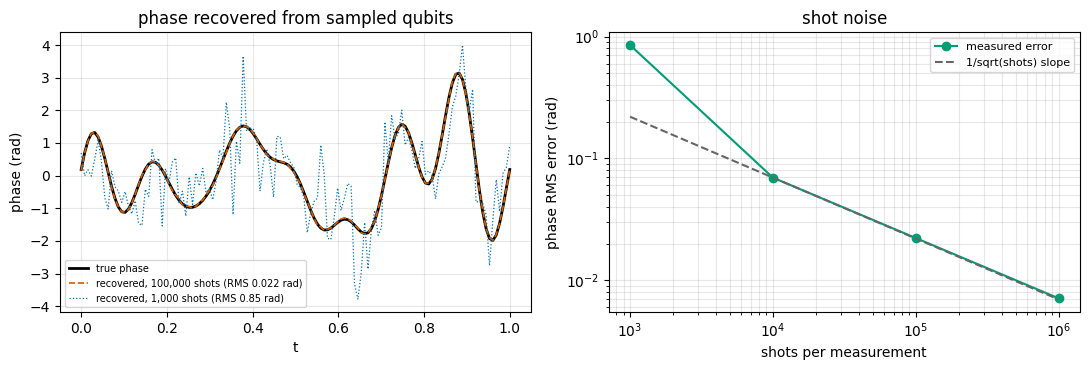

Figure: left, the true phase (solid black), the phase recovered from 100,000 shots (dashed orange, on top of it),
and from 1,000 shots (dotted blue, visibly wrong). Right, recovery error against shots on log axes (green circles),
following the 1/sqrt(shots) line (grey dashes) above about 10,000 shots.


In [3]:
near = lambda p: phi + np.angle(np.exp(1j*(p - phi)))      # same angle, drawn on the branch nearest the true phase (no +pi/-pi jumps)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(t, phi, color='#000000', lw=2, ls='-', label='true phase')
a1.plot(t, near(rows[2][2]), color='#D55E00', lw=1.2, ls='--', label=f'recovered, 100,000 shots (RMS {rows[2][1]:.3f} rad)')
a1.plot(t, near(rows[0][2]), color='#0072B2', lw=0.9, ls=':', label=f'recovered, 1,000 shots (RMS {rows[0][1]:.2f} rad)')
a1.set_xlabel('t'); a1.set_ylabel('phase (rad)'); a1.set_title('phase recovered from sampled qubits'); a1.legend(fontsize=7); a1.grid(alpha=0.3)
a2.loglog([r[0] for r in rows], [r[1] for r in rows], 'o-', color='#009E73', label='measured error')
a2.loglog([r[0] for r in rows], [rows[1][1]*np.sqrt(rows[1][0]/r[0]) for r in rows], color='0.4', ls='--', label='1/sqrt(shots) slope')
a2.set_xlabel('shots per measurement'); a2.set_ylabel('phase RMS error (rad)'); a2.set_title('shot noise'); a2.legend(fontsize=8); a2.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()
print('Figure: left, the true phase (solid black), the phase recovered from 100,000 shots (dashed orange, on top of it),')
print('and from 1,000 shots (dotted blue, visibly wrong). Right, recovery error against shots on log axes (green circles),')
print('following the 1/sqrt(shots) line (grey dashes) above about 10,000 shots.')

## The edge case, and the hardware cost

**Too little dispersion fails.** If D1 and D2 are small, the two recordings look almost the same and the algorithm has nothing to work with.

**Hardware cost.** Transpiled to standard gates, the circuit is far too deep for today's noisy quantum processors, which is a second reason this stays a simulation.

In [4]:
w1, w2 = Q.dispersion_circuit(n, -200.0), Q.dispersion_circuit(n, -230.0)
Ew, _ = Q.gs_retrieve(Q.measure_intensity(E, w1), Q.measure_intensity(E, w2), Operator(w1).data, Operator(w2).data)
print(f'weak dispersion (-200, -230): phase RMS error {Q.align_rms(np.angle(Ew), phi)[0]:.2f} rad  (fails)')

full = QuantumCircuit(n); full.append(StatePreparation(E/np.linalg.norm(E)), range(n)); full.compose(c1, inplace=True)
for label, qc in (('dispersion only', c1), ('state preparation + dispersion', full)):
    tq = transpile(qc, basis_gates=['rz', 'sx', 'x', 'cx'], optimization_level=1, seed_transpiler=0)
    print(f'{label}: depth {tq.depth()}, CNOT gates {tq.count_ops().get("cx", 0)}')

weak dispersion (-200, -230): phase RMS error 1.33 rad  (fails)
dispersion only: depth 330, CNOT gates 228
state preparation + dispersion: depth 855, CNOT gates 348


## Summary

- The dispersion D is the circuit QFT† · diag(e^{iπDν²}) · QFT on 7 qubits. It matches the NumPy model to about 10⁻¹³.
- Gerchberg-Saxton on the circuit's measurements recovers the phase exactly from the statevector, and to 0.022 rad from 100,000 shots. The error follows 1/√shots.
- Weak dispersion is ill-posed; the circuit is hundreds of CNOTs deep; there is no quantum speedup. Qiskit here is an exact, honest language for the same optics.

*Code: `dgs/qiskit_gs.py`; tests: `tests/test_qiskit_gs.py`; the classical version is `dgs/gs_core.py`.*